[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L5/BA_L5_events/BA_L5_events.ipynb)

# BA_L5_events: Event responses of the DPI

*Quantlet of Lecture 5, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Change of the mean De-pegging Pressure Index (DPI) over days 0 to 30 after six stress events relative to days -60 to -8, with heteroskedasticity and autocorrelation consistent (HAC) tests and the Holm correction, for two penalty grids of the Quantile Lasso, against the values reported by Fan, Sha, Härdle & Pele (2026); daily DPI from EODHD data in the event windows.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

## How robust are event responses?

**The De-pegging Pressure Index (DPI).** For each coin $j$ and day $t$, a 5% Quantile Lasso on the 90 days before $t$: the target is $d_{j,s}$; the predictors are the other coins' $d_{k,s}$ (same day) and the one-day-lagged changes of the US dollar index (DXY), the CBOE volatility index (VIX), the S&P 500 index (log changes) and the 1-year Treasury yield (first differences).
Every variable is centred by its window median and divided by $1.4826 \times$ its median absolute deviation (MAD). With the check loss $\rho_\tau(e) = e\,(\tau - \mathbb 1\{e < 0\})$,
$$ (\hat\alpha, \hat\beta)(\lambda) = \arg\min_{\alpha, \beta} \sum_{s \in W_t} \rho_{0.05}\big(d_{j,s} - \alpha - \mathbf x_{j,s}'\beta\big) + \lambda \sum_k |\beta_k| , $$
and $\hat\lambda_{j,t}$ minimises the generalised approximate cross-validation (GACV) criterion $\sum_s \rho_\tau(\hat e_s) / (n - \mathrm{df})$, $\mathrm{df} = \#\{\hat\beta_k \neq 0\} + 1$, over 25 values from $10^{-4}\lambda_{max}$ to $\lambda_{max}$. The index is the average selected penalty:
$$ \mathrm{DPI}_t = \frac{1}{J}\sum_{j=1}^{J} \hat\lambda_{j,t} . $$
The DPI is not a depeg probability; it is a model-implied measure of lower-tail dependence. Method of Fan, Sha, Härdle & Pele (2026); the penalty as a risk measure comes from the Financial Risk Meter (FRM) of [Mihoci, Althof, Chen & Härdle (2020)](https://doi.org/10.1108/S0731-905320200000042016).

**Event response.** For an event on day 0,
$$ \Delta = \overline{\mathrm{DPI}}_{[0, 30]} \big/ \overline{\mathrm{DPI}}_{[-60, -8]} - 1 . $$
The test regresses $\ln \mathrm{DPI}$ in the two windows on a post-event dummy with heteroskedasticity and autocorrelation consistent (HAC) errors (30 lags); the Holm correction adjusts the six p-values for multiple testing.
The estimation is repeated with a narrower grid of penalties, $[10^{-2}, 1]\,\lambda_{max}$ instead of $[10^{-4}, 1]\,\lambda_{max}$.

**Computation.** The DPI is estimated every day, but only inside the windows from 60 days before to 30 days after each event (546 days, about 3–6 minutes on two processor cores for both grids); the responses are the same as with the full daily index.
The share of boundary solutions and the correlation of the two indices are computed over these days; the slides report them over all 2,397 days (4.0% and 19.6% boundary solutions, correlation 0.84).
Paper values: Fan, Sha, Härdle & Pele (2026), CoinGecko prices, 11 coins.

**How to read the chart.** Three bars per event: the paper, the this course's replication with the wide grid, and with the narrow grid; the vertical axis is linear within ±20% and logarithmic beyond (symlog).

In [4]:
# Data: 10 stablecoins, their reference assets and four market variables, 1 January 2020 - 23 October 2026
import matplotlib
plt.rcParams['font.size'] = 10
END, END_PAPER = '2026-10-23', '2026-05-31'          # last day of the lecture sample; last day of the paper's sample
COINS = ['USDT', 'USDC', 'DAI', 'TUSD', 'USDP', 'GUSD', 'BUSD', 'SUSD', 'PAXG', 'EURS']
cal = pd.date_range('2020-01-01', END)


def weekdays(x):
    """EUR/USD and gold: Monday-Friday closes, repeated closes removed (the weekend bars come from a thin session)."""
    x = x[x.index.dayofweek < 5]
    return x[x.diff() != 0]


def finish_fig(fig, name, bottom, ncol=3):
    """Legend below the plot, then save and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)


ref = {'EURS': weekdays(daily('EURUSD.FOREX', END)), 'PAXG': weekdays(daily('XAUUSD.FOREX', END))}
P = pd.DataFrame({c: daily(f'{c}-USD.CC', END) for c in COINS}).reindex(cal).ffill(limit=7)    # past-only fill, at most 7 days
lr = 1e4 * np.log(P).diff()
bad = (lr.abs() > 1000) & (-lr.shift(-1) / lr >= 0.9)      # bad print: a move beyond 1000 bp, reversed by >= 90% the next day
P_raw = P.copy()                                           # prices as recorded
P = P.mask(bad).ffill(limit=7)                             # retrospective cleaning
Bm = pd.DataFrame({c: (ref[c].reindex(cal).ffill() if c in ref else pd.Series(1.0, index=cal)) for c in COINS})
D = 1e4 * (P / Bm - 1)                                     # reference-adjusted deviation d (bp)
D_raw = 1e4 * (P_raw / Bm - 1)                             # same, prices as recorded
R = 1e4 * np.log(P / Bm).diff()                            # reference-adjusted log return (bp)
mac = pd.DataFrame({'DXY': daily('DXY.INDX', END), 'VIX': daily('VIX.INDX', END), 'SPX': daily('GSPC.INDX', END),
                    'US1Y': daily('US1Y.GBOND', END)}).reindex(cal).ffill()
M = pd.DataFrame({'DXY': np.log(mac['DXY']).diff(), 'VIX': np.log(mac['VIX']).diff(), 'SPX': np.log(mac['SPX']).diff(),
                  'US1Y': mac['US1Y'].diff()}).shift(1)     # market changes, lagged one day
print(f'calendar {cal[0].date()} to {cal[-1].date()} ({len(cal)} days); bad prints removed: {int(bad.values.sum())}')

calendar 2020-01-01 to 2026-10-23 (2488 days); bad prints removed: 9


In [5]:
# 5% Quantile Lasso, penalty chosen by GACV, one equation per coin and day
from scipy.optimize import linprog
from joblib import Parallel, delayed
TAU, WIN, NGRID, LO = 0.05, 90, 25, 1e-4      # quantile level, window (days), grid size, lowest penalty / lambda_max
N_JOBS = os.cpu_count() or 1


def rho(e, tau=TAU):
    """Check loss."""
    return e * (tau - (e < 0))


def qlasso(X, y, lam):
    """Quantile Lasso as a linear programme: y = a+ - a- + X(b+ - b-) + u - v, minimise lam |b| + tau u + (1 - tau) v."""
    n, p = X.shape
    c = np.concatenate([[0, 0], lam * np.ones(2 * p), TAU * np.ones(n), (1 - TAU) * np.ones(n)])
    A = np.hstack([np.ones((n, 1)), -np.ones((n, 1)), X, -X, np.eye(n), -np.eye(n)])
    z = linprog(c, A_eq=A, b_eq=y, bounds=[(0, None)] * len(c), method='highs').x
    return z[0] - z[1], z[2:2 + p] - z[2 + p:2 + 2 * p]


def robust(Z):
    """Centre by the median, divide by 1.4826 x MAD (by the sd if the MAD is zero); drop constant columns."""
    med = np.median(Z, axis=0)
    mad = 1.4826 * np.median(np.abs(Z - med), axis=0)
    s = np.where(mad > 0, mad, Z.std(axis=0))
    keep = s > 0
    return (Z[:, keep] - med[keep]) / s[keep], keep


def fit_eq(y, X, lo=LO):
    """GACV-selected penalty on 25 values in [lo, 1] x lambda_max: returns (lambda, GACV, slopes, grid position)."""
    n = len(y)
    if X.shape[1] == 0:
        return np.nan, rho(y - np.quantile(y, TAU)).sum() / (n - 1), np.array([]), -1
    lmax = np.abs(X.T @ (TAU - (y < np.quantile(y, TAU)))).max()
    best = None
    for k, lam in enumerate(np.geomspace(lmax * lo, lmax, NGRID)):
        a, b = qlasso(X, y, lam)
        df = 1 + (np.abs(b) > 1e-8).sum()
        g = rho(y - a - X @ b).sum() / (n - df)
        if best is None or g < best[1]:
            best = (lam, g, b, k)
    return best


def window(t_idx):
    """Deviations of the 90 days before day t as known on day t: cleaned, except the last day (not yet checkable)."""
    Dw = D.iloc[t_idx - WIN:t_idx].copy()
    Dw.iloc[-1] = D_raw.iloc[t_idx - 1]
    return Dw


def day(t_idx, blocks=('coin', 'macro'), lo=LO):
    """All coin equations of calendar row t_idx: target d_j, predictors the other coins' d and the lagged market changes."""
    Dw = window(t_idx)
    out = {}
    for c in COINS:
        y = Dw[c].values
        if np.isnan(y).any():
            continue
        y = (y - np.median(y)) / (1.4826 * np.median(np.abs(y - np.median(y))) or y.std() or 1)
        parts, names = [], []
        if 'coin' in blocks:
            Xc = Dw.drop(columns=c)
            ok = ~np.isnan(Xc.values).any(axis=0)
            parts.append(Xc.values[:, ok]); names += list(Xc.columns[ok])
        if 'macro' in blocks:
            parts.append(M.values[t_idx - WIN:t_idx]); names += list(M.columns)
        Zs, keep = robust(np.hstack(parts))
        names = [nm for nm, k in zip(names, keep) if k]
        lam, g, b, k = fit_eq(y, Zs, lo)
        out[c] = dict(lam=lam, gacv=g, k=k, coef=dict(zip(names, b)))
    return t_idx, out


def run_days(idx, lo=LO):
    """Estimate all equations on the calendar rows idx, in parallel on all processor cores."""
    chunks = [c for c in np.array_split(np.asarray(idx), 4 * N_JOBS) if len(c)]
    out = Parallel(n_jobs=N_JOBS)(delayed(lambda ix: [day(i, lo=lo) for i in ix])(c) for c in chunks)
    return {i: o for part in out for i, o in part}


first = cal.get_loc(pd.Timestamp('2020-04-01'))           # first DPI day: 90 days of history
weekly = [i for i in range(first, len(cal)) if (cal[i] - pd.Timestamp('2020-06-29')).days % 7 == 0]   # days before the rebalancings

In [6]:
EVENTS = {'KuCoin hack': '2020-09-26', 'China sell-off': '2021-05-19', 'Terra collapse': '2022-05-09',
          'FTX crisis': '2022-11-08', 'SVB / USDC depeg': '2023-03-11', 'Iran-Hormuz shock': '2026-02-28'}

import time
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
ev_days = sorted({cal.get_loc(t_) for d0 in EVENTS.values()
                  for t_ in pd.date_range(pd.Timestamp(d0) - pd.Timedelta(days=60), pd.Timestamp(d0) + pd.Timedelta(days=30))})
t0 = time.time()
res_w = run_days(ev_days)                                    # wide grid
res_n = run_days(ev_days, lo=1e-2)                           # narrow grid
print(f'{len(ev_days)} days x {len(COINS)} coins x 2 grids estimated in {time.time() - t0:.0f} s')
dpi_of = lambda r_: pd.DataFrame({cal[i]: {c: v['lam'] for c, v in o.items()} for i, o in r_.items()}).T[COINS].sort_index().mean(axis=1)
DPI_w, DPI_n = dpi_of(res_w), dpi_of(res_n)


def responses(dpi):
    rows = {}
    for name, d0 in EVENTS.items():
        t0_ = pd.Timestamp(d0)
        pre = dpi.loc[t0_ - pd.Timedelta(days=60):t0_ - pd.Timedelta(days=8)]
        post = dpi.loc[t0_:t0_ + pd.Timedelta(days=30)]
        seg = np.log(pd.concat([pre, post]))
        dm = np.r_[np.zeros(len(pre)), np.ones(len(post))]
        fr = sm.OLS(seg.values, sm.add_constant(dm)).fit(cov_type='HAC', cov_kwds={'maxlags': 30})
        rows[name] = {'date': d0, 'change (%)': 100 * (post.mean() / pre.mean() - 1), 't-statistic': fr.tvalues[1], 'p-value': fr.pvalues[1]}
    out = pd.DataFrame(rows).T
    out['Holm p-value'] = multipletests(out['p-value'].astype(float), method='holm')[1]
    return out


EV = responses(DPI_w)
EV['change, narrow grid (%)'] = responses(DPI_n)['change (%)']
EV['paper: change (%)'] = pd.Series({'KuCoin hack': -14.4, 'China sell-off': -8.6, 'Terra collapse': 2.2, 'FTX crisis': 19.5,
                                     'SVB / USDC depeg': 11.0, 'Iran-Hormuz shock': -22.9})

546 days x 10 coins x 2 grids estimated in 83 s


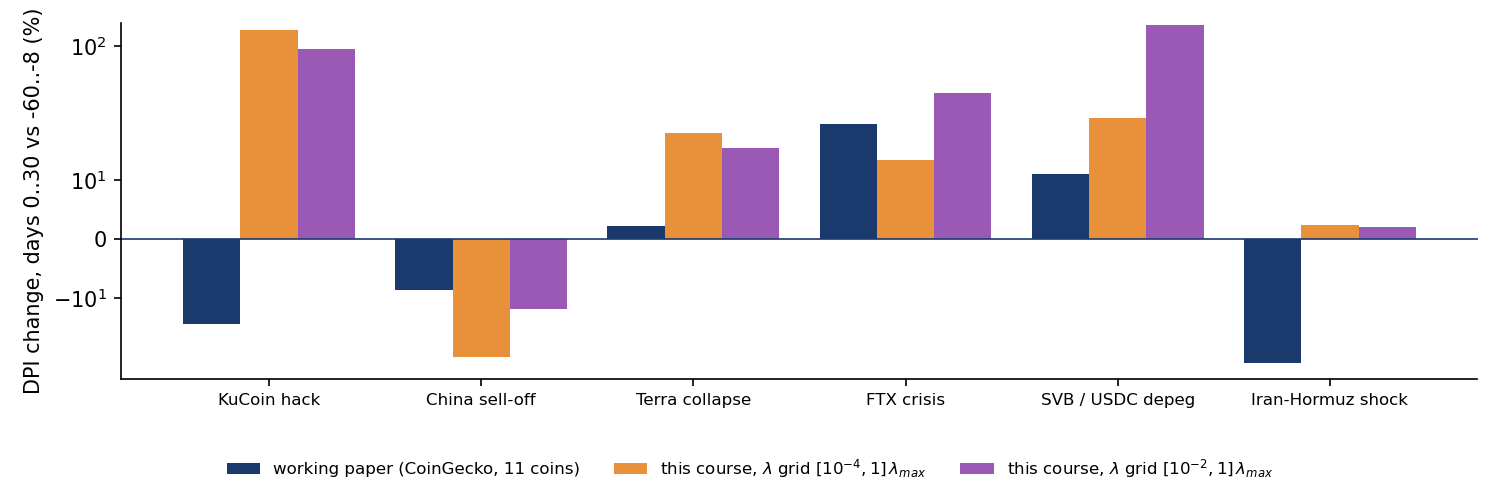

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.3))
xx = np.arange(len(EVENTS))
ax.bar(xx - 0.27, EV['paper: change (%)'].astype(float), width=0.27, color=BLUE, label='working paper (CoinGecko, 11 coins)')
ax.bar(xx, EV['change (%)'].astype(float), width=0.27, color=BTC, label=r'this course, $\lambda$ grid $[10^{-4}, 1]\,\lambda_{max}$')
ax.bar(xx + 0.27, EV['change, narrow grid (%)'].astype(float), width=0.27, color=ETH, label=r'this course, $\lambda$ grid $[10^{-2}, 1]\,\lambda_{max}$')
ax.axhline(0, color=BLUE, lw=0.8)
ax.set_xticks(xx); ax.set_xticklabels(list(EVENTS), fontsize=8); ax.set_ylabel('DPI change, days 0..30 vs -60..-8 (%)')
ax.set_yscale('symlog', linthresh=20)                        # linear within +-20%, logarithmic beyond
finish_fig(fig, 'ba_l5_events', 0.13, ncol=3)

In [8]:
edge_w = 100 * np.mean([v['k'] == 0 for o in res_w.values() for v in o.values()])
edge_n = 100 * np.mean([v['k'] == 0 for o in res_n.values() for v in o.values()])
print(f'event-window days: share of equations that select the smallest lambda (boundary solution): wide grid {edge_w:.1f}%, narrow grid {edge_n:.1f}%')
print(f'correlation of log DPI, wide vs narrow grid, event-window days: {np.corrcoef(np.log(DPI_w), np.log(DPI_n))[0, 1]:.2f}')
EV.round(3)

event-window days: share of equations that select the smallest lambda (boundary solution): wide grid 4.4%, narrow grid 18.8%
correlation of log DPI, wide vs narrow grid, event-window days: 0.81


,date,change (%),t-statistic,p-value,Holm p-value,"change, narrow grid (%)",paper: change (%)
KuCoin hack,2020-09-26,141.114762,5.417596,0.0,0.000,95.293415,-14.4
China sell-off,2021-05-19,-20.196054,-2.644367,0.008184,0.033,-11.85052,-8.6
Terra collapse,2022-05-09,17.885748,2.858348,0.004259,0.021,15.394794,2.2
FTX crisis,2022-11-08,13.383015,0.705785,0.480322,0.961,36.73157,19.5
SVB / USDC depeg,2023-03-11,20.998567,2.161821,0.030632,0.092,158.601194,11.0
Iran-Hormuz shock,2026-02-28,2.354069,0.214763,0.829952,0.961,1.922011,-22.9


The sign agrees with the paper for 4 of the 6 events, but sizes and significance change with the data source and even with the grid of penalties: the SVB response is $+21\%$ with one grid and $+159\%$ with the other. Event responses should be reported with their specification.